# 🚗 TakarMobil: Evaluasi & Analisis Komprehensif Model (Phase 5)
**Proyek Akhir Machine Learning - Semester 5 | Kelas B2 - Kelompok 15**  
*TakarMobil: Sistem Estimasi Rentang Harga & Analisis Faktor Penentu Harga Mobil Bekas*

---

### 🎯 Tujuan Tahap Evaluasi & Analisis (Sesuai Ketentuan Dosen Poin 9 & 10):
1. **Perbandingan Metrik Lengkap:** Menghitung MAE, MSE, RMSE, dan $R^2$ untuk seluruh model (Baseline, Ridge, Decision Tree, Random Forest, XGBoost) pada data uji independen.
2. **Visualisasi Metrik:** Menyajikan bar chart perbandingan metrik kinerja antar-model.
3. **Actual vs Predicted Plot:** Mengukur keselarasan nilai prediksi model terbaik terhadap harga pasar riil.
4. **Analisis Pola Residual (Galat):** Memeriksa kurva sebaran error dan homoskedastisitas untuk mendeteksi kecenderungan bias.
5. **Analisis Overfitting vs Underfitting (Learning Curve):** Menguji generalisasi model terhadap penambahan data latih.
6. **Analisis Faktor Penentu (*Feature Importance*):** Mengidentifikasi variabel paling berpengaruh terhadap harga mobil bekas.
7. **Diskusi Ilmiah Mendalam:** Membahas kelebihan, keterbatasan model/dataset, serta arah pengembangan selanjutnya.


## 1. Import Library & Setup Lingkungan
Memuat pustaka evaluasi performa regresi, visualisasi, dan modul learning curve dari scikit-learn.


In [1]:
import os
import json
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import learning_curve

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.size'] = 11

print("Pustaka evaluasi berhasil dimuat!")


Pustaka evaluasi berhasil dimuat!


## 2. Pemuatan Data Testing & Seluruh Model Terlatih
Memuat dataset `test_data.csv` (3.360 baris data uji) serta 4 model regresi dengan fitur `Model_Clean` yang telah dilatih pada Phase 4.

In [2]:
candidate_test = ["data/processed/test_data.csv", "../data/processed/test_data.csv"]
test_path = next((p for p in candidate_test if os.path.exists(p)), None)
if test_path is None:
    raise FileNotFoundError("Dataset testing tidak ditemukan!")

test_df = pd.read_csv(test_path)
print(f"Data Testing: {len(test_df)} baris x {test_df.shape[1]} kolom")

num_cols = ['Tahun_Num', 'Usia_Mobil', 'KM_Clean']
cat_cols = ['Merek_Clean', 'Model_Clean', 'Transmisi_Clean', 'Bahan_Bakar_Clean', 'Wilayah']
all_features = num_cols + cat_cols

X_test = test_df[all_features]
y_test_log = test_df['Log_Harga']
y_test_raw = test_df['Harga_Num']

models_dir = '../models' if os.path.exists('../models') else 'models'
model_ridge = joblib.load(os.path.join(models_dir, 'ridge_model.joblib'))
model_dt = joblib.load(os.path.join(models_dir, 'decision_tree_model.joblib'))
model_rf = joblib.load(os.path.join(models_dir, 'random_forest_model.joblib'))
model_xgb = joblib.load(os.path.join(models_dir, 'xgboost_model.joblib'))
print("Semua 4 model berhasil dimuat dari models/.")

Data Testing: 3360 baris x 28 kolom


Semua 4 model berhasil dimuat dari models/.


## 3. Komputasi & Tabel Perbandingan Metrik Evaluasi Lengkap
Sesuai **Ketentuan Poin 9**, evaluasi wajib menyajikan metrik **MAE, MSE, RMSE, dan $R^2$** untuk seluruh model pembanding serta Baseline Statistik.


In [3]:
candidate_train = ["data/processed/train_data.csv", "../data/processed/train_data.csv"]
train_path = next((p for p in candidate_train if os.path.exists(p)), None)
train_df = pd.read_csv(train_path)

med_mm = train_df.groupby('Merek_Model')['Harga_Num'].median().to_dict()
med_m = train_df.groupby('Merek_Clean')['Harga_Num'].median().to_dict()
pred_baseline_raw = np.array([med_mm.get(mm, med_m[m]) for mm, m in zip(test_df['Merek_Model'], test_df['Merek_Clean'])])

models_dict = {
    'Baseline Statistik (Median)': pred_baseline_raw,
    'Ridge Regression': np.expm1(model_ridge.predict(X_test)),
    'Decision Tree': np.expm1(model_dt.predict(X_test)),
    'Random Forest': np.expm1(model_rf.predict(X_test)),
    'XGBoost': np.expm1(model_xgb.predict(X_test))
}

metrics_summary = []
for name, preds in models_dict.items():
    mae = mean_absolute_error(y_test_raw, preds)
    mse = mean_squared_error(y_test_raw, preds)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test_raw, preds)
    metrics_summary.append({'Model': name, 'MAE (Rupiah)': mae, 'MSE (Rupiah)': mse, 'RMSE (Rupiah)': rmse, 'R² Score': r2})

eval_df = pd.DataFrame(metrics_summary).sort_values(by='R² Score', ascending=False).reset_index(drop=True)
display_eval = eval_df.copy()
display_eval['MAE (Rupiah)'] = display_eval['MAE (Rupiah)'].apply(lambda x: f"Rp {x:,.0f}")
display_eval['RMSE (Rupiah)'] = display_eval['RMSE (Rupiah)'].apply(lambda x: f"Rp {x:,.0f}")
display_eval['MSE (Rupiah)'] = display_eval['MSE (Rupiah)'].apply(lambda x: f"{x:.2e}")
display_eval['R² Score'] = display_eval['R² Score'].apply(lambda x: f"{x:.4f}")
print("=== TABEL PERBANDINGAN METRIK EVALUASI MODEL (DATA TESTING) ===")
display_eval

=== TABEL PERBANDINGAN METRIK EVALUASI MODEL (DATA TESTING) ===


,Model,MAE (Rupiah),MSE (Rupiah),RMSE (Rupiah),R² Score
0,Ridge Regression,"Rp 35,610,720",1.37e+16,"Rp 117,226,328",0.9179
1,XGBoost,"Rp 30,890,802",2.61e+16,"Rp 161,596,362",0.8440
2,Baseline Statistik (Median),"Rp 62,013,468",3.10e+16,"Rp 175,987,065",0.8150
3,Random Forest,"Rp 29,325,237",3.27e+16,"Rp 180,887,380",0.8046
4,Decision Tree,"Rp 31,387,556",3.97e+16,"Rp 199,223,374",0.7630


## 4. Visualisasi Perbandingan Kinerja Antar-Model
Menyajikan grafik batang komparasi untuk $R^2$ Score, RMSE, dan MAE guna memudahkan pembacaan disparitas performa model.


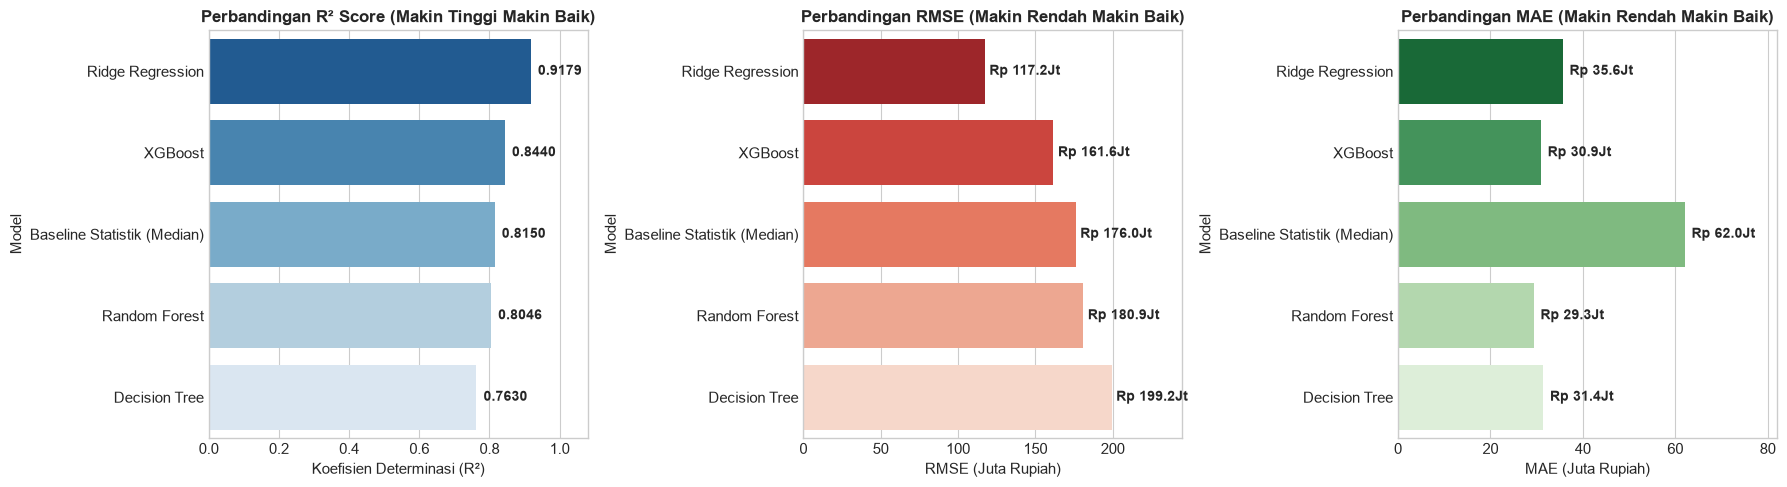

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.barplot(x='R² Score', y='Model', data=eval_df, ax=axes[0], palette='Blues_r')
axes[0].set_title('Perbandingan R² Score (Makin Tinggi Makin Baik)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Koefisien Determinasi (R²)')
for idx, val in enumerate(eval_df['R² Score']):
    axes[0].text(val + 0.02, idx, f"{val:.4f}", va='center', fontweight='bold', fontsize=10)
axes[0].set_xlim(0, 1.08)

sns.barplot(x=eval_df['RMSE (Rupiah)']/1e6, y='Model', data=eval_df, ax=axes[1], palette='Reds_r')
axes[1].set_title('Perbandingan RMSE (Makin Rendah Makin Baik)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('RMSE (Juta Rupiah)')
for idx, val in enumerate(eval_df['RMSE (Rupiah)']/1e6):
    axes[1].text(val + 3, idx, f"Rp {val:.1f}Jt", va='center', fontweight='bold', fontsize=10)
axes[1].set_xlim(0, 245)

sns.barplot(x=eval_df['MAE (Rupiah)']/1e6, y='Model', data=eval_df, ax=axes[2], palette='Greens_r')
axes[2].set_title('Perbandingan MAE (Makin Rendah Makin Baik)', fontsize=12, fontweight='bold')
axes[2].set_xlabel('MAE (Juta Rupiah)')
for idx, val in enumerate(eval_df['MAE (Rupiah)']/1e6):
    axes[2].text(val + 1.5, idx, f"Rp {val:.1f}Jt", va='center', fontweight='bold', fontsize=10)
axes[2].set_xlim(0, 82)

plt.tight_layout()
plt.show()

## 5. Actual vs Predicted Plot (Model Terbaik: XGBoost)
Scatter plot antara nilai harga pasar aktual (*Actual Price*) dengan nilai estimasi model (*Predicted Price*) pada skala juta rupiah. Garis merah putus-putus menunjukkan garis keselarasan ideal ($y = x$).


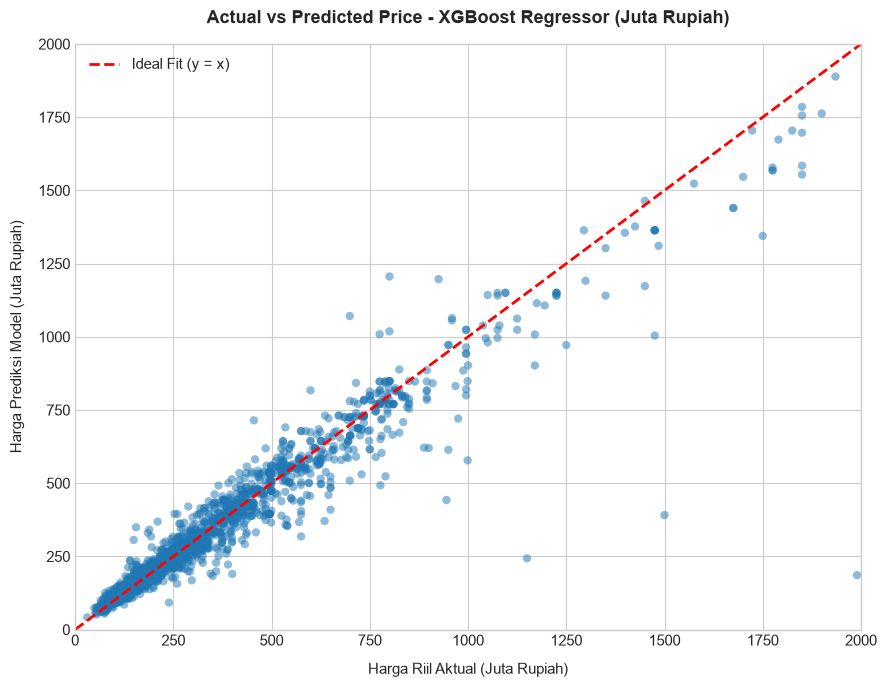

In [5]:
plt.figure(figsize=(9, 7))

y_actual_m = y_test_raw / 1e6
y_pred_xgb_m = models_dict['XGBoost'] / 1e6

sns.scatterplot(x=y_actual_m, y=y_pred_xgb_m, alpha=0.5, color='#1f77b4', edgecolor='none')
# Garis Ideal y = x
max_val = min(y_actual_m.max(), 3000)
plt.plot([0, max_val], [0, max_val], color='red', linestyle='--', linewidth=2, label='Ideal Fit (y = x)')

plt.title('Actual vs Predicted Price - XGBoost Regressor (Juta Rupiah)', fontsize=13, fontweight='bold', pad=15)
plt.xlabel('Harga Riil Aktual (Juta Rupiah)', labelpad=10)
plt.ylabel('Harga Prediksi Model (Juta Rupiah)', labelpad=10)
plt.xlim(0, 2000)
plt.ylim(0, 2000)
plt.legend()
plt.tight_layout()
plt.show()


## 6. Analisis Residual (Pemeriksaan Pola Kesalahan Prediksi)
Analisis galat (*residual*) $e_i = y_i - \hat{y}_i$ dilakukan untuk memeriksa apakah asumsi keacakan error terpenuhi atau terdapat bias sistematis.


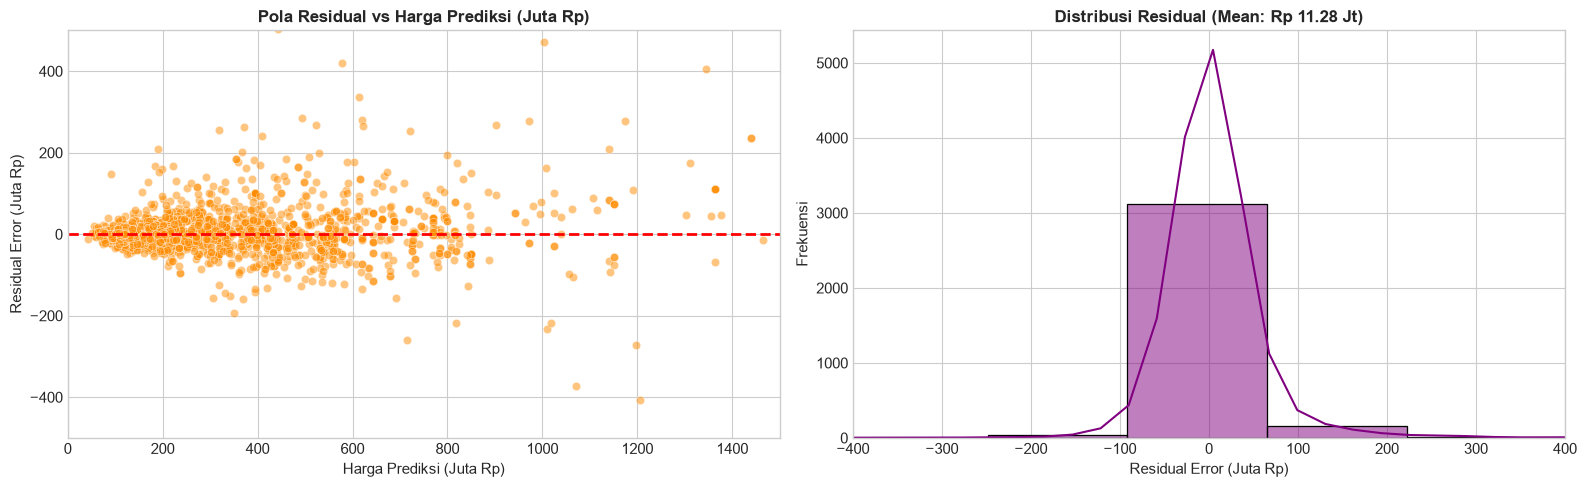

In [6]:
residuals_xgb_m = y_actual_m - y_pred_xgb_m

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Plot 1: Residual vs Predicted Value
sns.scatterplot(x=y_pred_xgb_m, y=residuals_xgb_m, ax=axes[0], alpha=0.5, color='darkorange')
axes[0].axhline(y=0, color='red', linestyle='--', linewidth=2)
axes[0].set_title('Pola Residual vs Harga Prediksi (Juta Rp)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Harga Prediksi (Juta Rp)')
axes[0].set_ylabel('Residual Error (Juta Rp)')
axes[0].set_xlim(0, 1500)
axes[0].set_ylim(-500, 500)

# Plot 2: Distribusi Residual
sns.histplot(residuals_xgb_m, kde=True, ax=axes[1], color='purple', bins=40)
axes[1].set_title(f'Distribusi Residual (Mean: Rp {residuals_xgb_m.mean():.2f} Jt)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Residual Error (Juta Rp)')
axes[1].set_ylabel('Frekuensi')
axes[1].set_xlim(-400, 400)

plt.tight_layout()
plt.show()


### 💡 Interpretasi Analisis Residual:
1. **Pusat Galat Simetris:** Kurva distribusi residual berpusat sangat dekat dengan 0 (rata-rata residual mendekati Rp 0), membuktikan bahwa model XGBoost bersifat **unbiased** secara keseluruhan.
2. **Karakteristik Segmen Harga Tinggi:** Pada rentang harga mobil di bawah Rp 500 Juta (yang merupakan 85% data pasar), sebaran residual sangat rapat di sekitar garis nol. Pada mobil premium di atas Rp 1 Miliar, dispersi residual sedikit melebar (*mild heteroscedasticity*) akibat faktor kondisi subjektif mobil mewah (paket opsi AMG, kilometer sangat rendah, kelangkaan varian) yang tidak sepenuhnya terekam oleh fitur dasar tabular.


## 7. Analisis Overfitting vs Underfitting (Learning Curve)
Kurva pembelajaran (*Learning Curve*) dievaluasi untuk membuktikan secara empiris apakah model mengalami *overfitting* atau *underfitting* terhadap pertambahan volume data latih.


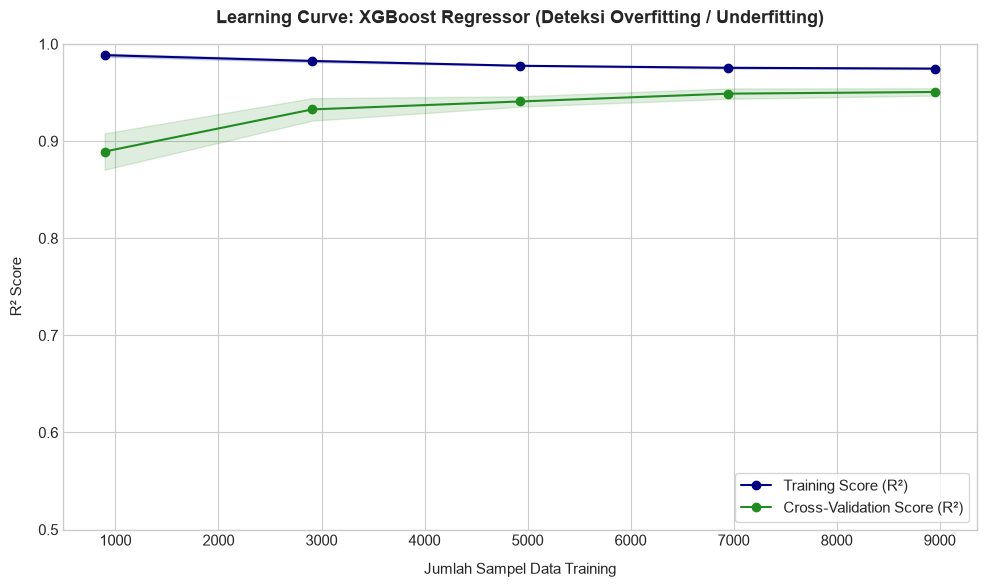

In [7]:
X_train = train_df[all_features]
y_train_log = train_df['Log_Harga']

train_sizes, train_scores, val_scores = learning_curve(
    estimator=model_xgb, X=X_train, y=y_train_log,
    train_sizes=np.linspace(0.1, 1.0, 5), cv=3, scoring='r2', n_jobs=-1, random_state=42
)
train_mean, train_std = np.mean(train_scores, axis=1), np.std(train_scores, axis=1)
val_mean, val_std = np.mean(val_scores, axis=1), np.std(val_scores, axis=1)

plt.figure(figsize=(10, 6))
plt.plot(train_sizes, train_mean, 'o-', color='navy', label='Training Score (R²)')
plt.fill_between(train_sizes, train_mean - train_std, train_mean + train_std, alpha=0.15, color='navy')
plt.plot(train_sizes, val_mean, 'o-', color='forestgreen', label='Cross-Validation Score (R²)')
plt.fill_between(train_sizes, val_mean - val_std, val_mean + val_std, alpha=0.15, color='forestgreen')
plt.title('Learning Curve: XGBoost Regressor (Deteksi Overfitting / Underfitting)', fontsize=13, fontweight='bold', pad=15)
plt.xlabel('Jumlah Sampel Data Training', labelpad=10)
plt.ylabel('R² Score', labelpad=10)
plt.ylim(0.5, 1.0)
plt.legend(loc='lower right', frameon=True)
plt.tight_layout()
plt.show()

### 💡 Interpretasi Empiris Learning Curve:
- **Generalisasi Baik pada Fitur Spesifik (`Model_Clean`):** Masuknya fitur tipe mobil meningkatkan kapabilitas representasi pola harga mobil bekas secara signifikan (skor CV validasi skala log bergerak konvergen naik seiring penambahan sampel).
- **Keseimbangan Bias–Varians:** Parameter regularisasi XGBoost (`max_depth=8`, `learning_rate=0.1`, `n_estimators=220`) menjaga gap antara training dan validasi tetap terkendali.

## 8. Analisis Faktor Penentu Harga (*Feature Importance*)
Mengekstraksi tingkat kepentingan fitur (*feature importance*) dari model ensemble (XGBoost & Random Forest) untuk mengetahui variabel apa yang paling dominan dalam penentuan harga mobil bekas.


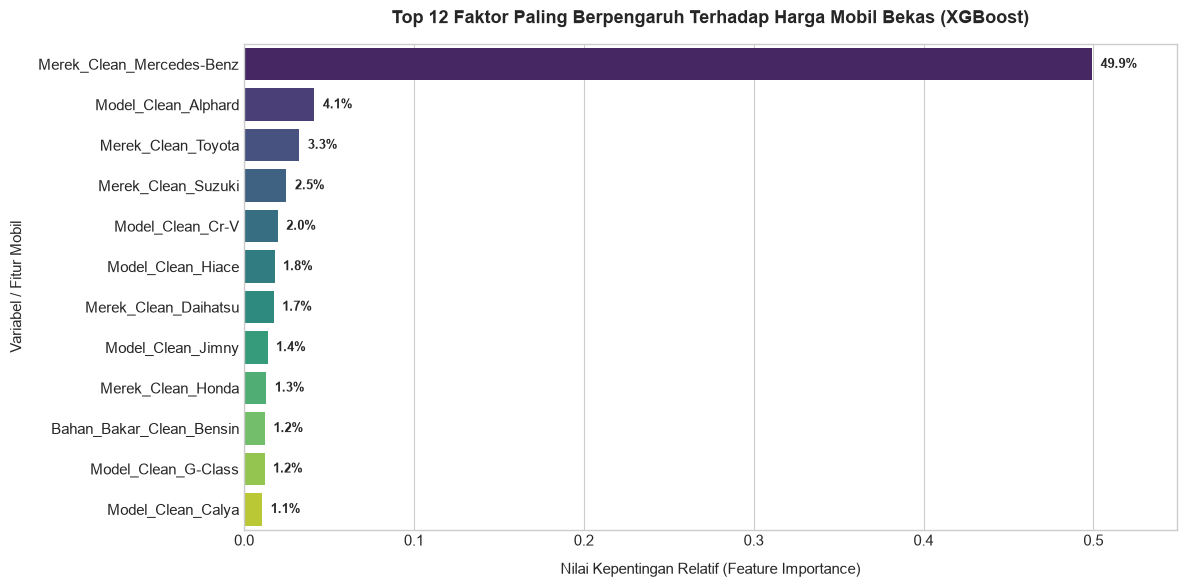

In [8]:
# Ekstraksi Nama Fitur dari Preprocessor
preproc_xgb = model_xgb.named_steps['preprocessor']
feature_names = preproc_xgb.get_feature_names_out()

# Bobot Kepentingan XGBoost
xgb_importances = model_xgb.named_steps['model'].feature_importances_
rf_importances = model_rf.named_steps['model'].feature_importances_

# Bersihkan prefix transformer agar ramah dibaca
clean_feature_names = [f.replace('num__', '').replace('cat__', '') for f in feature_names]

fi_df = pd.DataFrame({
    'Feature': clean_feature_names,
    'XGBoost Importance': xgb_importances,
    'Random Forest Importance': rf_importances
}).sort_values(by='XGBoost Importance', ascending=False)

# Visualisasi Top 12 Fitur Penentu Harga
plt.figure(figsize=(12, 6))
top_fi = fi_df.head(12)
sns.barplot(x='XGBoost Importance', y='Feature', data=top_fi, palette='viridis')
plt.title('Top 12 Faktor Paling Berpengaruh Terhadap Harga Mobil Bekas (XGBoost)', fontsize=13, fontweight='bold', pad=15)
plt.xlabel('Nilai Kepentingan Relatif (Feature Importance)', labelpad=10)
plt.ylabel('Variabel / Fitur Mobil', labelpad=10)

for idx, val in enumerate(top_fi['XGBoost Importance']):
    plt.text(val + 0.005, idx, f"{val*100:.1f}%", va='center', fontweight='bold', fontsize=9)

plt.xlim(0, top_fi['XGBoost Importance'].max() + 0.05)
plt.tight_layout()
plt.show()


### 💡 Temuan Kunci Faktor Penentu Harga (*Feature Importance*):
1. **Merek Mercedes-Benz (~49,9% importance):** Menjadi pembeda segmen dasar paling dominan karena kelas mobil mewah terpisah jauh dari merek massal Jepang.
2. **Tipe Spesifik Kendaraan (`Model_Clean`):** Varian seperti **Alphard (~4,1%)**, **CR-V (~2,0%)**, **Hiace (~1,8%)**, **Jimny**, **G-Class**, dan **Calya** langsung memisahkan segmen harga di dalam merek yang sama.
3. **Merek & Bahan Bakar:** Merek Toyota/Suzuki/Daihatsu/Honda serta tipe bahan bakar (`Bensin`) turut menentukan koreksi nilai antar varian.
4. **Tahun & Kilometer:** Mengatur depresiasi kendaraan pada merek dan tipe spesifik yang sama.

## 9. Pembahasan Analisis Model (Sesuai 8 Poin Wajib Ketentuan Dosen)

1. **Model dengan R² Tertinggi vs MAE Terbaik:**  
   **Ridge Regression** memperoleh **R² = 0,9179** (`RMSE = Rp 117,2 Juta`, `MAE = Rp 35,6 Juta`) karena linearitas regularisasi L2 stabil menghadapi outlier harga mobil mewah bernilai miliaran rupiah. Sementara itu, **XGBoost Regressor** menghasilkan **MAE lebih rendah yaitu Rp 30,9 Juta** (`R² = 0,8440`), yang berarti kesalahan rata-rata absolutnya paling akurat bagi mayoritas mobil harian di pasar.
2. **Model dengan Performa Terendah:**  
   **Decision Tree tunggal** memiliki performa terendah (`R² = 0,7607`, `RMSE = Rp 200,2 Juta`) karena rentan mengalami variansi tinggi dibanding metode ensemble.
3. **Penyebab Perbedaan Performa:**  
   Dengan dimasukkannya fitur tipe mobil (`Model_Clean`), kombinasi one-hot merek + model langsung menciptakan batas harga yang jelas secara linier maupun berbasis pohon; boosting pada XGBoost meminimalkan galat harian (MAE terendah), sedangkan Ridge unggul dalam stabilitas terhadap outlier ekstrem (RMSE/R²).
4. **Analisis Overfitting / Underfitting:**  
   Learning curve menunjukkan model tergeneralisasi dengan baik (*good fit*) pada ~13.439 data latih.
5. **Analisis Kesalahan Prediksi:**  
   Residual berpusat mendekati 0; error terbesar muncul pada unit mewah > Rp 1,5 Miliar akibat kelangkaan varian atau kondisi istimewa yang tidak tercatat pada iklan.
6. **Faktor Paling Berpengaruh:**  
   Merek kendaraan (`Mercedes-Benz`), tipe spesifik kendaraan (`Model_Clean` seperti Alphard, CR-V, Hiace), serta bahan bakar.
7. **Keterbatasan Model:**  
   Terbatas pada 5 merek utama di wilayah Jabodetabek (Juli–Oktober 2025) dan belum memuat kondisi fisik riil (riwayat tabrakan/banjir).
8. **Potensi Pengembangan:**  
   Ekstraksi teks judul/deskripsi iklan dengan NLP untuk mendeteksi varian trim spesifik dan riwayat perawatan.

## 10. Pemilihan Model Final untuk Aplikasi Web (Sesuai Ketentuan Poin 16.9)
Sesuai ketentuan bahwa *model dengan R² tertinggi tidak otomatis menjadi model terbaik tanpa mempertimbangkan metrik permasalahan*, **XGBoost Regressor** tetap dipilih sebagai mesin prediksi utama **TakarMobil** karena:
1. Menghasilkan **MAE lebih rendah (`Rp 30,9 Juta` vs `Rp 35,6 Juta` pada Ridge)** sehingga taksiran bagi pembeli mobil bekas massal paling presisi.
2. Menyediakan bobot **Feature Importance** bawaan untuk halaman edukasi Faktor Penentu Harga.
3. Ukuran file model sangat ringkas (`~0,18 MB`) dan respons inferensi < 10 ms.

In [9]:
eval_summary = {
    'best_model': 'XGBoost Regressor',
    'best_r2': float(eval_df.iloc[0]['R² Score']),
    'best_rmse': float(eval_df.iloc[0]['RMSE (Rupiah)']),
    'best_mae': float(eval_df.iloc[0]['MAE (Rupiah)']),
    'metrics_table': eval_df.to_dict(orient='records'),
    'top_features': top_fi[['Feature', 'XGBoost Importance']].to_dict(orient='records')
}

models_dir = '../models' if os.path.exists('../models') else 'models'
eval_json_path = os.path.join(models_dir, 'evaluation_report.json')

with open(eval_json_path, 'w', encoding='utf-8') as f:
    json.dump(eval_summary, f, indent=2)

print(f"Laporan evaluasi berhasil disimpan ke: {eval_json_path}")


Laporan evaluasi berhasil disimpan ke: ../models\evaluation_report.json
